Shape: (512, 512)
Dtype: float32
Min: -1024.0
Max: 1758.0
Gray Shape: (512, 512)
Gray Dtype: float32
Gray Min: -1024.0
Gray Max: 1758.0
Norm Shape: (512, 512)
Norm Dtype: uint8
Norm Min: 0
Norm Max: 255


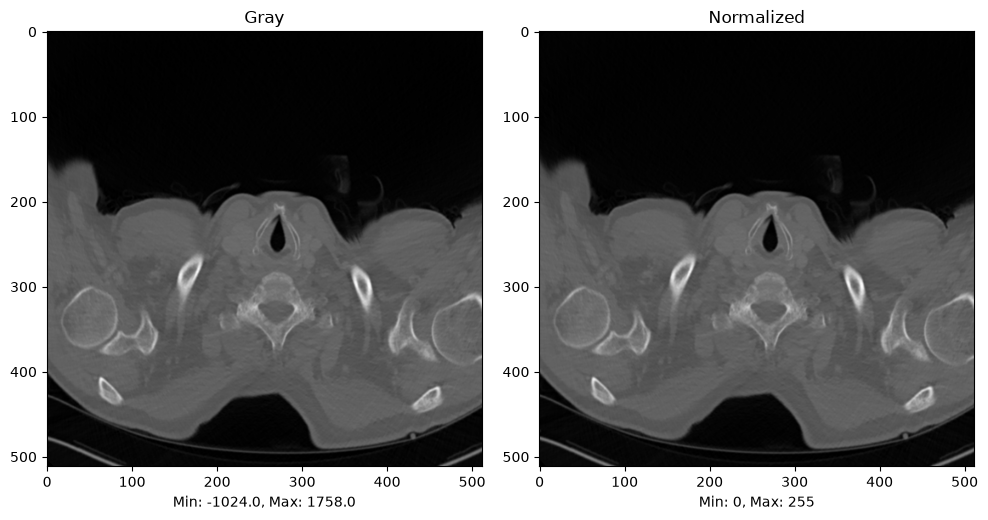

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

import pydicom

path = "/Users/bredegronningen/Documents/Datateklokal/Big Data:Smart Tech/Lectures/Harnverhalt/0001.dcm"
ds = pydicom.dcmread(path)  # les DICOM-fila: bilete + metadata
raw = ds.pixel_array       # berre pikseltala, som numpy-array

# Bruk metadata dersom fila har Hounsfield-konvertering.
slope = float(getattr(ds, "RescaleSlope", 1))
intercept = float(getattr(ds, "RescaleIntercept", 0))
img = raw.astype(np.float32) * slope + intercept

# 1) DICOM-biletet er allereie eit enkelt gråtonebilete.
print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Min:", img.min())
print("Max:", img.max())

# 2) Ingen cv2.cvtColor er nødvendig: img er allereie gråtone.
gray = img.copy()
print("Gray Shape:", gray.shape)
print("Gray Dtype:", gray.dtype)
print("Gray Min:", gray.min())
print("Gray Max:", gray.max())

# 3) Normaliser til 0-255.
norm = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)
print("Norm Shape:", norm.shape)
print("Norm Dtype:", norm.dtype)
print("Norm Min:", norm.min())
print("Norm Max:", norm.max())

# 4) Vis gray og norm side om side.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(gray, cmap="gray")
ax1.set_title("Gray")
ax1.set_xlabel(f"Min: {gray.min()}, Max: {gray.max()}")
ax2.imshow(norm, cmap="gray")
ax2.set_title("Normalized")
ax2.set_xlabel(f"Min: {norm.min()}, Max: {norm.max()}")
plt.tight_layout()
plt.show()

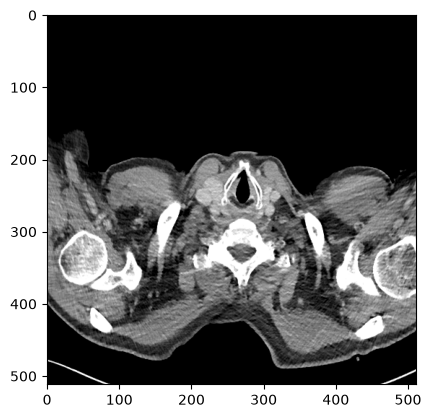

In [6]:
#bløtvevvidu
plt.imshow(img, cmap="gray", vmin=-160, vmax=240)   # senter 40, bredde 400

In [7]:
print(img[250:255, 250:255])

[[119. 118. 123.  96.  76.]
 [128. 137. 111.  65.  22.]
 [109. 109.  74.  -6. -56.]
 [ 95.  51. -16. -47. -73.]
 [114.  42.  -1. -33. -46.]]


Tal på funne filer: 281


/Users/bredegronningen/opt/anaconda3/envs/bigdata/lib/python3.11/site-packages/pydicom/filereader.py:487: UserWarning: End of file reached before delimiter (FFFE,E0DD) found in file /Users/bredegronningen/Documents/Datateklokal/Big Data:Smart Tech/Lectures/Harnverhalt/0281.dcm
  warn_and_log(msg, UserWarning)


Fila manglar Pixel Data: /Users/bredegronningen/Documents/Datateklokal/Big Data:Smart Tech/Lectures/Harnverhalt/0281.dcm


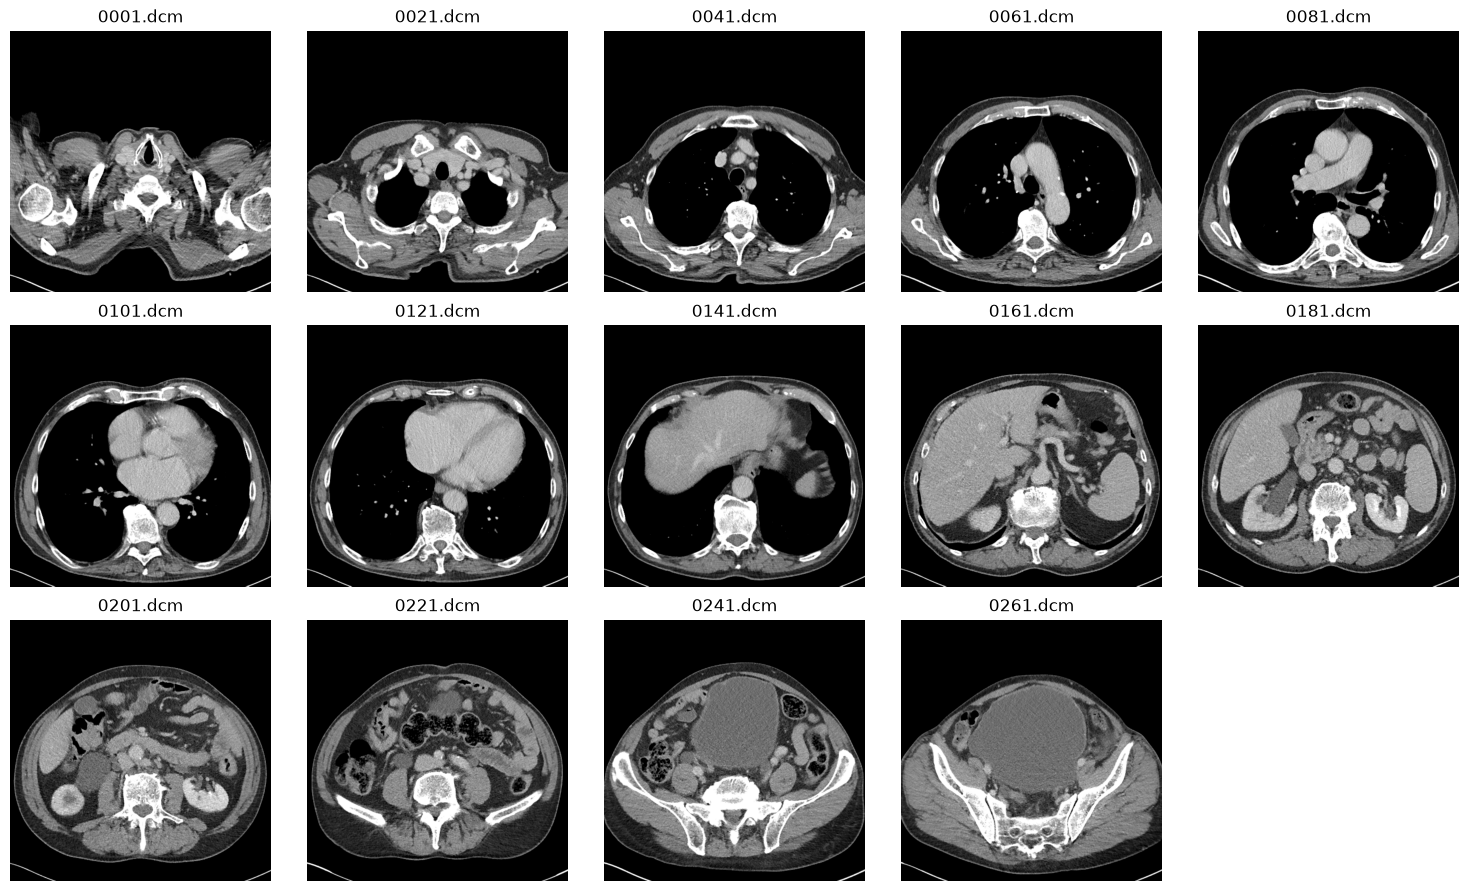

In [8]:
import glob

path = "/Users/bredegronningen/Documents/Datateklokal/Big Data:Smart Tech/Lectures/Harnverhalt/*.dcm"

# 1) Lag en funksjon: sti inn -> HU-array ut.
#    Hvorfor: du kommer til å laste bilder hundrevis av ganger. Skriv det én gang.
def last_hu(path):
    ds = pydicom.dcmread(path)  # les DICOM-fila: bilete + metadata
    if "PixelData" not in ds:
        raise ValueError(f"Fila manglar Pixel Data: {path}")

    raw = ds.pixel_array       # berre pikseltala, som numpy-array

    # Bruk metadata dersom fila har Hounsfield-konvertering.
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))
    hu = raw.astype(np.float32) * slope + intercept
    return hu

# 2) Lag en vindusfunksjon. Ikke bruk vmin/vmax denne gangen.
#    Hvorfor: k-means skal få de vindusbehandlede TALLENE, ikke bare en visning.
#    Hint: np.clip(hu, senter - bredde/2, senter + bredde/2), skaler så til 0–255, til slutt .astype(np.uint8)
def window(hu, center=40, width=400):
    low = center - width/2
    high = center + width/2
    clipped = np.clip(hu, low, high)
    scaled = (clipped - low) / (high - low) * 255
    return scaled.astype(np.uint8)

# 3) Vis hvert 20. snitt i et rutenett, så du finner hvor blæren er.
filer = sorted(glob.glob(path))
print("Tal på funne filer:", len(filer))
fig, axs = plt.subplots(3, 5, figsize=(15, 9))
for ax, sti in zip(axs.flat, filer[::20]):   # kvar runde: eitt panel + éi fil
    try:
        bilde = window(last_hu(sti))
    except ValueError as error:
        print(error)
        ax.axis("off")
        continue

    ax.imshow(bilde, cmap="gray")
    ax.set_title(sti.split("/")[-1])
    ax.axis("off")
plt.tight_layout()
plt.show()

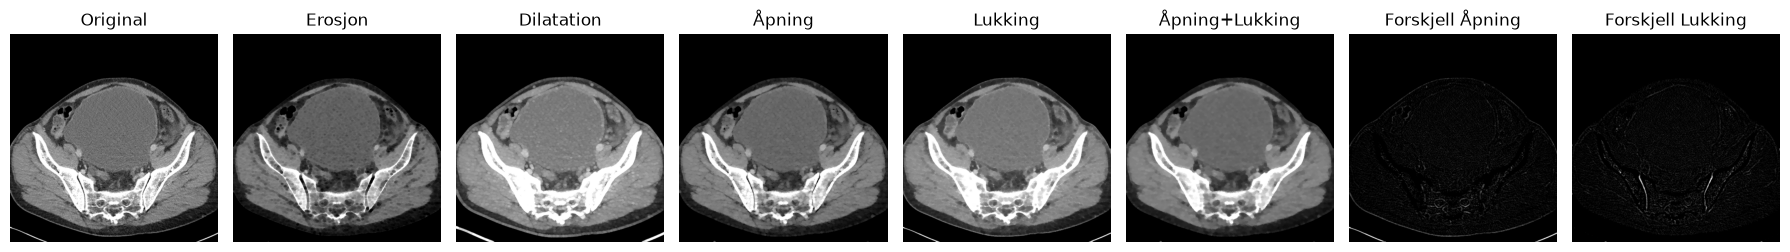

'\nfor ax, (tittel, bilde) in zip(axs.flat, [("Original", window(last_hu(bladder))),\n                                        ("Erosjon", cv2.erode(window(last_hu(bladder)), k)),\n                                        ("Dilatation", cv2.dilate(window(last_hu(bladder)), k)),\n                                        ("Åpning", cv2.morphologyEx(window(last_hu(bladder)), cv2.MORPH_OPEN, k)),\n                                        ("Lukking", cv2.morphologyEx(window(last_hu(bladder)), cv2.MORPH_CLOSE, k))]):\n    ax.imshow(bilde, cmap="gray")\n    ax.set_title(tittel)\n    ax.axis("off")\n\n\nplt.tight_layout()\nplt.show()'

In [9]:
#Morfologi

'''Bruk window(last_hu(...0261.dcm)) og vis seks paneler ved siden av hverandre: original, erosjon, dilasjon, opening, closing, og ett panel med opening og så closing etter hverandre.'''

bladder = "/Users/bredegronningen/Documents/Datateklokal/Big Data:Smart Tech/Lectures/Harnverhalt/0261.dcm"

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))   # formen: en 5x5-sirkel

# bilde = window(last_hu(bladder))  # Vis vindusbehandlet bilde for blæren

original = window(last_hu(bladder))
erosjon = cv2.erode(original, k)
dilatation =  cv2.dilate(original, k)
open = cv2.morphologyEx(original, cv2.MORPH_OPEN, k)
lukking = cv2.morphologyEx(original, cv2.MORPH_CLOSE, k)
begge = cv2.morphologyEx(open, cv2.MORPH_CLOSE, k)   # closing brukt på resultatet av opening
#tripledilatasjon = cv2.dilate(cv2.dilate(original, k), k)  # dilasjon brukt tre ganger på rad
diff_open  = cv2.absdiff(original, open)   # absolutt forskjell, piksel for piksel
diff_close = cv2.absdiff(original, lukking)

panels = [("Original", original),
          ("Erosjon", erosjon),
          ("Dilatation", dilatation),
          ("Åpning", open),
          ("Lukking", lukking),
          ("Åpning+Lukking", begge),
          ("Forskjell Åpning", diff_open),
          ("Forskjell Lukking", diff_close),
          ]

fig, axs = plt.subplots(1, len(panels), figsize=(18, 3))
for ax, (tittel, bilde) in zip(axs.flat, panels):
    ax.imshow(bilde, cmap="gray")
    ax.set_title(tittel)
    ax.axis("off")
plt.tight_layout(); plt.show()

#window(last_hu(bladder))  # Vis vindusbehandlet bilde for blæren

'''Løkken skriver du selv, med samme mønster som rutenettet i stad. Hint: lag en liste med par, [("Original", bilde), ("Erosjon", ...), ...], og gå gjennom den med zip(axs, liste).'''
'''
for ax, (tittel, bilde) in zip(axs.flat, [("Original", window(last_hu(bladder))),
                                        ("Erosjon", cv2.erode(window(last_hu(bladder)), k)),
                                        ("Dilatation", cv2.dilate(window(last_hu(bladder)), k)),
                                        ("Åpning", cv2.morphologyEx(window(last_hu(bladder)), cv2.MORPH_OPEN, k)),
                                        ("Lukking", cv2.morphologyEx(window(last_hu(bladder)), cv2.MORPH_CLOSE, k))]):
    ax.imshow(bilde, cmap="gray")
    ax.set_title(tittel)
    ax.axis("off")


plt.tight_layout()
plt.show()'''

Ein ser at at closing-transfomasjonen visker vekk overgangen til blæren som er nyttgi for clustering m k-means. Videre til clusteringen:

[[  0.6806488]
 [101.31469  ]
 [237.38458  ]
 [ 45.386528 ]
 [135.25967  ]]
[[-158.93231 ]
 [  -1.074997]
 [ 212.36798 ]
 [ -88.80545 ]
 [  52.172028]]


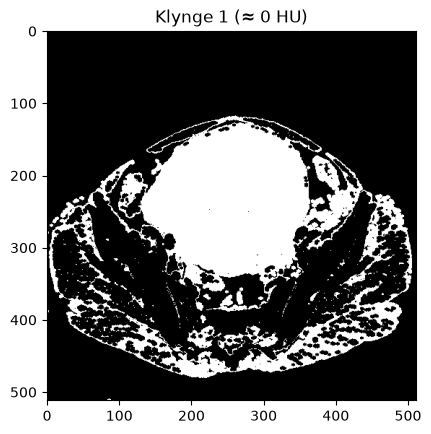

In [10]:
from sklearn.cluster import KMeans

X = open.reshape(-1, 1).astype(np.float32)
# bilde (512, 512) -> tabell (262144, 1). -1 betyr "regn ut selv".
# sklearn krever formen (rader, kolonner), altså observasjoner × features.

km = KMeans(n_clusters=5, n_init=10, random_state=0)
# n_init=10: kjør 10 ganger med ulike startpunkter og behold det beste.
#   Hvorfor: k-means er følsom for start (slide 70: "sensitive to initial centroid placement").
# random_state=0: gir samme resultat hver gang du kjører, slik at du kan sammenligne.

labels = km.fit_predict(X)            # én klyngelabel (0, 1, 2) per rad
seg = labels.reshape(open.shape)     # tabell -> bilde igjen
print(km.cluster_centers_)            # de 3 sentrene, i gråverdi 0–255


hu_sentre = -160 + km.cluster_centers_ / 255 * 400
print(hu_sentre)

bladder_label = 1 # posisjon i lista: 101 står på plass 1 (vi teller fra 0)
mask = (seg == bladder_label)       # True der pikselen tilhører klyngen, ellers False
plt.imshow(mask, cmap="gray"); plt.title("Klynge 1 (≈ 0 HU)"); plt.show()

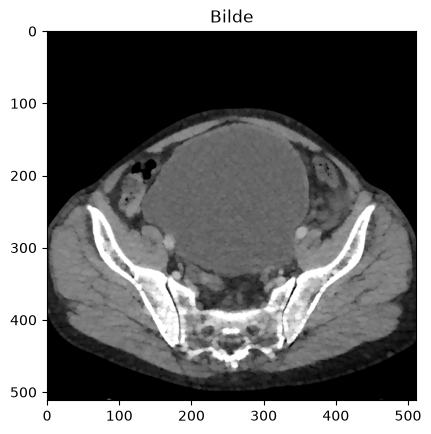

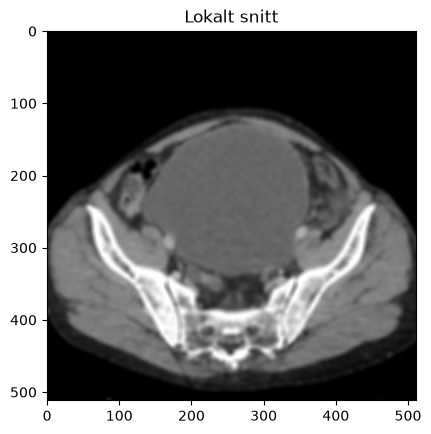

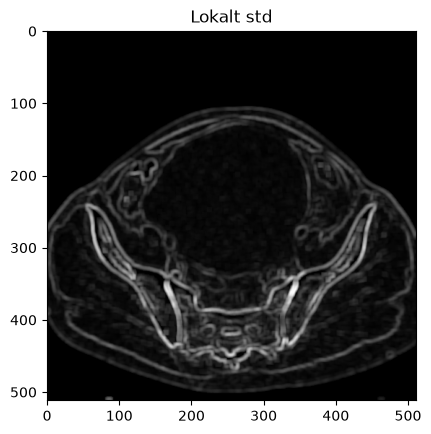

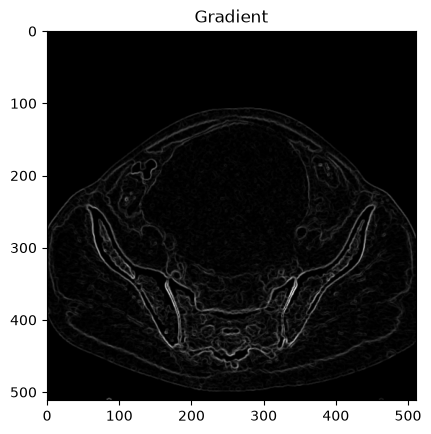

[[1.   0.99 0.56 0.38]
 [0.99 1.   0.57 0.4 ]
 [0.56 0.57 1.   0.8 ]
 [0.38 0.4  0.8  1.  ]]
[69.2 67.6 12.5 69.4]


In [11]:
b = open.astype(np.float32)          # din åpnede variabel; float for å regne trygt

snitt = cv2.blur(b, (7, 7))            # lokalt snitt: hver piksel = gjennomsnittet i 7x7 rundt
std   = np.sqrt(np.maximum(cv2.blur(b**2, (7, 7)) - snitt**2, 0))
# std = sqrt(E[x²] − E[x]²), altså standardavvik-formelen fra statistikken, brukt lokalt.
# np.maximum(..., 0) hindrer små negative tall fra avrunding før kvadratroten.

gx = cv2.Sobel(b, cv2.CV_32F, 1, 0)    # endring i x-retning
gy = cv2.Sobel(b, cv2.CV_32F, 0, 1)    # endring i y-retning
grad = np.sqrt(gx**2 + gy**2)          # styrken på endringen (Pytagoras)

F = np.stack([b, snitt, std, grad], axis=-1)   # (512, 512, 4): fire tall per piksel
X = F.reshape(-1, 4)                           # (262144, 4): tabellen

plt.imshow(F[:, :, 0], cmap="gray"); plt.title("Bilde"); plt.show()
plt.imshow(F[:, :, 1], cmap="gray"); plt.title("Lokalt snitt"); plt.show()
plt.imshow(F[:, :, 2], cmap="gray"); plt.title("Lokalt std"); plt.show()
plt.imshow(F[:, :, 3], cmap="gray"); plt.title("Gradient"); plt.show()

print(np.corrcoef(X.T).round(2))


#normalisering kreves av pca
print(X.std(axis=0).round(1))    # spredningen i hver kolonne

In [12]:
#normalisering for PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Xs = StandardScaler().fit_transform(X)       # z-skår per kolonne
pca = PCA(n_components=4).fit(Xs)

print(pca.explained_variance_ratio_.round(3))  # andel av variansen hver PC forklarer
print(pca.components_.round(2))
# rader = PC1..PC4, kolonner = intensitet, snitt, std, grad
# tallene er vekter: hvor mye hver feature bidrar til komponenten

[0.716 0.238 0.043 0.002]
[[ 0.52  0.53  0.51  0.44]
 [-0.48 -0.45  0.42  0.63]
 [-0.09 -0.1   0.75 -0.64]
 [-0.7   0.71 -0.   -0.02]]


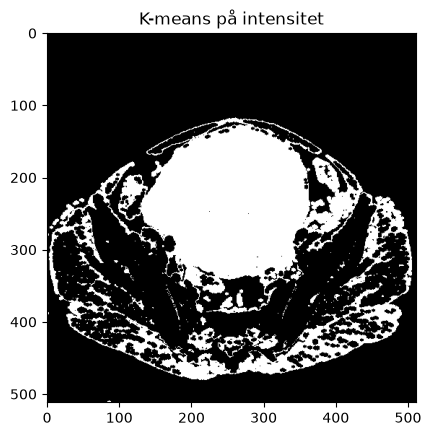

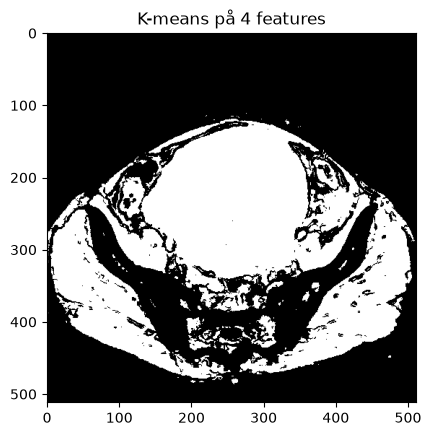

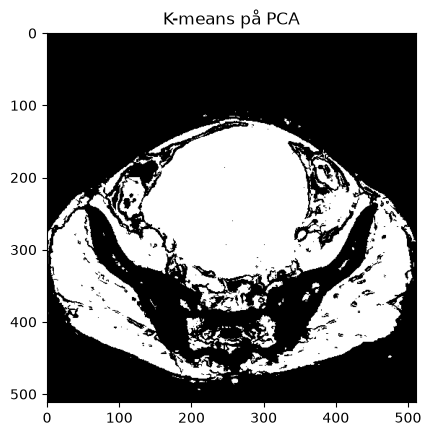

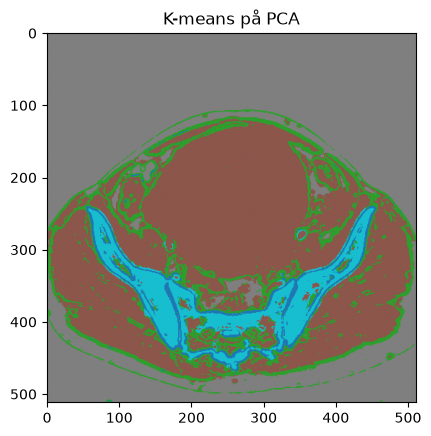

In [13]:
Z = PCA(n_components=2).fit_transform(Xs)    # (262144, 2): bare PC1 og PC2 per piksel
km_pca = KMeans(n_clusters=5, n_init=10, random_state=0)
seg_pca = km_pca.fit_predict(Z).reshape(b.shape)

bladder_label = seg_pca[225, 250]  # finn klyngen som inneholder blæren (piksel 250, 250)

def bladder_mask(features, rad, kol, k=5):
    """features: tabell (antall piksler, antall kolonner). Returnerer en True/False-maske for blæreklyngen."""
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    seg = km.fit_predict(features).reshape(b.shape)   # klynge, og gjør om til bilde igjen
    label = seg[rad, kol]                             # hvilken klynge blærepikselen havnet i
    return seg == label                               # maske: True der klyngen er

mask_1 = bladder_mask(b.reshape(-1,1), 225, 250, k=5)
mask_2 = bladder_mask(Xs, 225, 250, k=5)
mask_pca = bladder_mask(Z, 225, 250, k=5)

for mask, tittel in zip([mask_1, mask_2, mask_pca], ["K-means på intensitet", "K-means på 4 features", "K-means på PCA"]):
    plt.imshow(mask, cmap="gray"); plt.title(tittel); plt.show()

plt.imshow(seg_pca, cmap="tab10"); plt.title("K-means på PCA"); plt.show()


In [14]:
#sammenligning av maskene
import time

# 1) Hvor mange piksler er med i hver maske?
print(mask_1.sum(), mask_2.sum(), mask_pca.sum())

# 2) Dice-koeffisient: overlapp mellom to masker, fra 0 (ingen overlapp) til 1 (identiske).
#    Standardmålet i medisinsk segmentering.
def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum())

print(dice(mask_2, mask_pca))


#tidskostnad for k-means på 4 features vs PCA
t0 = time.time()
mask_2 = bladder_mask(Xs, 225, 250, k=5)
print("4 features:", time.time() - t0, "sek")

t0 = time.time()
mask_pca = bladder_mask(Xs, 225, 250, k=5)
print("PCA:", time.time() - t0, "sek")


65255 91231 92153
0.9913405749683724
4 features: 0.7509307861328125 sek
PCA: 0.6392121315002441 sek


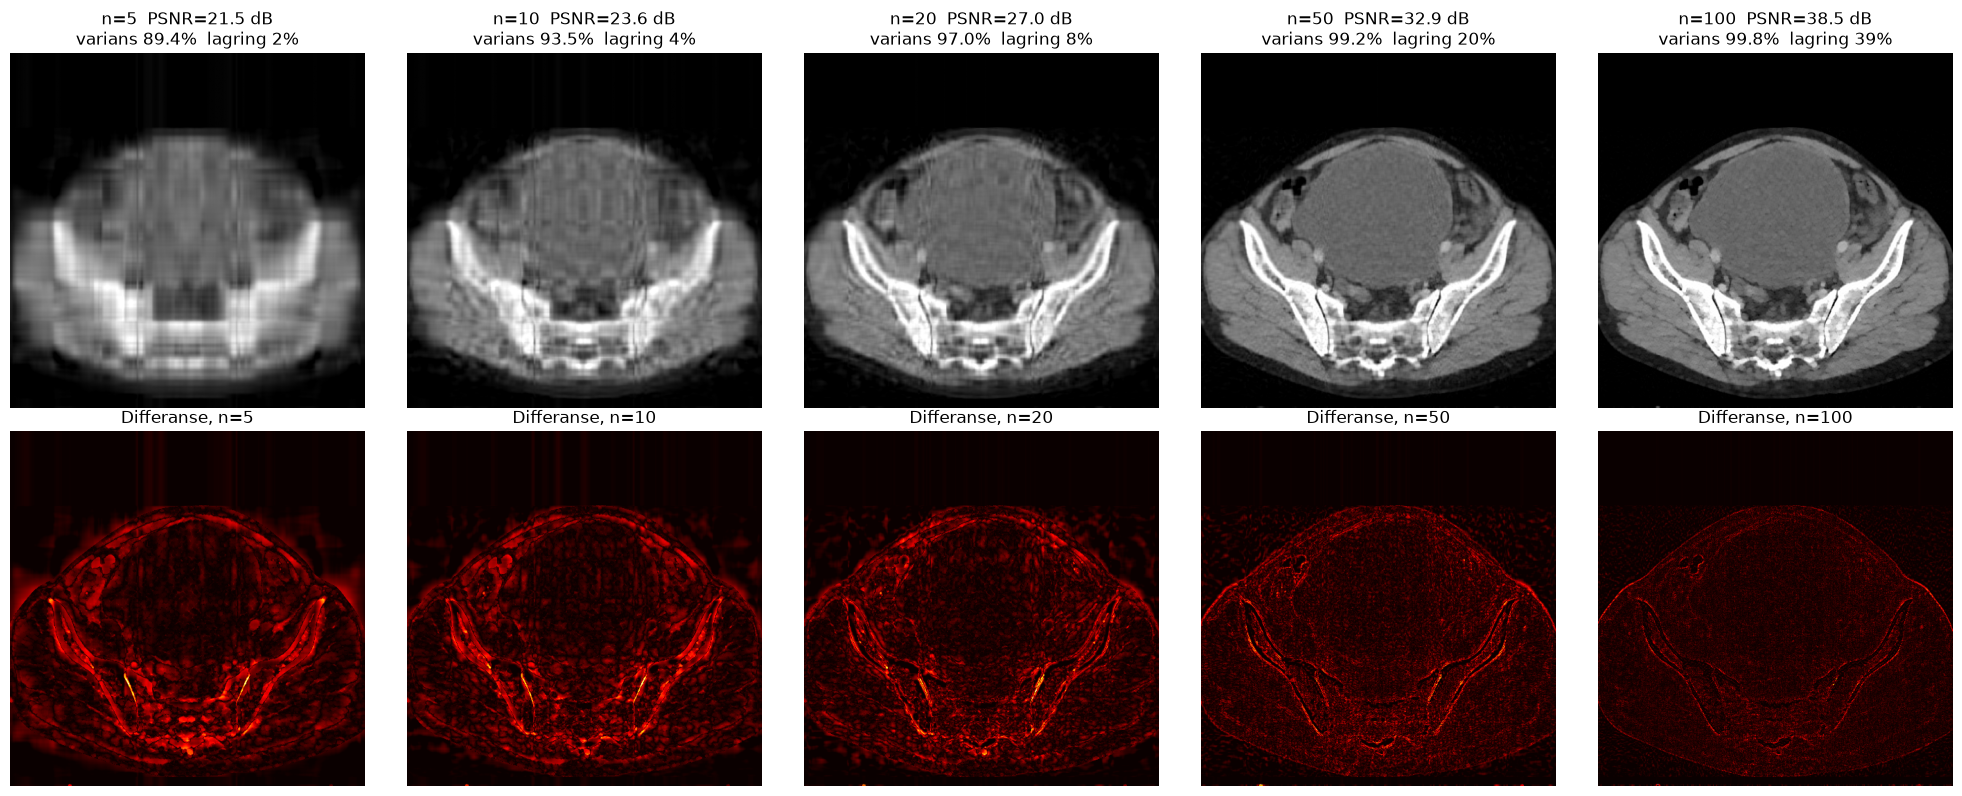

In [15]:
#Rekonstruksjon og differanse


def pca_rekonstruksjon(bilde, n):
    """Komprimer bildet til n komponenter med PCA og bygg det opp igjen."""
    pca = PCA(n_components=n)
    Z = pca.fit_transform(bilde)        # (512, n): hver bilderad beskrevet med n tall
    rek = pca.inverse_transform(Z)      # (512, 512): bildet bygget opp igjen
    return np.clip(rek, 0, 255), pca.explained_variance_ratio_.sum()

    

def psnr(original, rek):
    """Peak Signal-to-Noise Ratio i dB. Høyere er bedre. Over ~30 dB er tapet knapt synlig."""
    mse = np.mean((original - rek) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

ns = [5, 10, 20, 50, 100]
fig, axs = plt.subplots(2, len(ns), figsize=(20, 8))

for i, n in enumerate(ns):
    rek, var = pca_rekonstruksjon(b, n)
    diff = np.abs(b - rek)                         # differansebilde: det PCA mistet
    lagring = (512 * n + n * 512 + 512) / (512 * 512)   # andel av original lagring

    axs[0, i].imshow(rek, cmap="gray")
    axs[0, i].set_title(f"n={n}  PSNR={psnr(b, rek):.1f} dB\nvarians {var:.1%}  lagring {lagring:.0%}")
    axs[1, i].imshow(diff, cmap="hot")
    axs[1, i].set_title(f"Differanse, n={n}")
    for ax in axs[:, i]: ax.axis("off")

plt.tight_layout(); plt.show()

